# F4 · Madde 4 — 21 öznitelikli cihaz modeli: federe öğrenme ve INT8 deneyleri (10 tohum)
**Profesörün notu:** *21 öznitelikli cihaz modelini federated ve INT8 deneylerine de dahil et.*

Cihaz öznitelik kümesi yalnız bir IoT düğümünün kendisinin sayabileceği 10 akış sayacından oluşur (protokol, süre, bayt,
paket, bağlantı durumu); DNS/SSL/HTTP alanları yoktur. Bu defter F3 ile **aynı kodu** (`trustids/pipeline.py`) cihaz
öznitelikleriyle çalıştırır: FL (aynı protokoller), FP32/INT8, sağlamlık, ablasyon ve risk–kapsama.

* **Aynı satırlar:** cihaz öznitelikleri ana bölmenin aynı satırlarından hesaplanır (02 defterindeki öznitelik karşılaştırmasıyla
  aynı yöntem); merkezi cihaz modeli 02 defterinde her tohum için eğitilip kaydedilen modeldir. Defter, yeniden hesaplanan
  skorların 02'de kaydedilen skorlarla aynı olduğunu **doğrular**.
* **Aynı istemciler:** non-IID bölme anahtarı (service) cihaz kümesinde yoktur; istemci ataması ana öznitelik kümesindeki
  service kategorisinden alınır. Böylece F3 ile F4 aynı istemcileri karşılaştırır.
* **Sınırlılık:** tekrar temizliği 53 öznitelikli vektörler üzerinde yapıldı; 21 öznitelikte bazı test vektörleri bir eğitim
  vektörüyle birebir aynı olabilir. Bu pay aşağıda raporlanır. A1 (Isolation Forest) bu kümede eğitilmediği için tabloda yoktur.
* Son bölüm, F3 sonuçları varsa **cihaz − tümü** farkını eşleştirilmiş testlerle verir.

In [1]:
# ---- Kurulum (her defterde aynı): Drive'ı bağla, ortak kodu içe aktar ----
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
PROJECT_DIR = os.environ.get("TRUSTIDS_PROJECT", "/content/drive/MyDrive/TrustFed-TinyIDS-Final")
QUICK = os.environ.get("TRUSTIDS_QUICK", "0") == "1"   # hızlı mod YALNIZCA kodu test etmek içindir
# Devam modu: Colab oturumu kapanırsa, Drive'a kaydedilmiş tohumlar/adımlar atlanır ve kalan yerden devam edilir.
# Her şeyi baştan hesaplamak için: os.environ["TRUSTIDS_RESUME"] = "0"
RESUME = os.environ.get("TRUSTIDS_RESUME", "1") == "1"
sys.path.insert(0, PROJECT_DIR)

from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from trustids.config import Config
from trustids import utils

# Veri kümesi seçimi: varsayılan TON_IoT; ikinci veri kümesi için TRUSTIDS_CONFIG=edge_iiotset.json
CONFIG_NAME = os.environ.get("TRUSTIDS_CONFIG", "default.json")
CFG_PATH = Path(PROJECT_DIR) / "configs" / CONFIG_NAME
if CONFIG_NAME != "default.json" and not CFG_PATH.exists():
    raise FileNotFoundError(f"{CFG_PATH} bulunamadı: configs/ klasörünü de Drive'a yükleyin.")
cfg = Config.load(CFG_PATH) if CFG_PATH.exists() else Config(project_dir=PROJECT_DIR)
cfg.project_dir = PROJECT_DIR
if QUICK:
    cfg.train_seeds, cfg.validity_resplits, cfg.epochs = cfg.train_seeds[:2], 30, 15
    cfg.random_control_repeats, cfg.bootstrap_repeats = 10, 200
    cfg.lofo_seeds, cfg.fl_orig_rounds = cfg.lofo_seeds[:2], 3
    cfg.resolution_cal_windows, cfg.resolution_eval_windows = 600, 600
cfg.check()
ART = cfg.artifacts
FIG = Path(PROJECT_DIR) / cfg.figures_dir; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Proje klasörü:", PROJECT_DIR, "| hızlı mod:", QUICK, "| devam modu:", RESUME)
print("Drive'da kayıtlı ilerleme:", utils.progress(cfg))

Mounted at /content/drive
Proje klasörü: /content/drive/MyDrive/TrustFed-TinyIDS-Final | hızlı mod: False | devam modu: True
Drive'da kayıtlı ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': True}


In [2]:
import tensorflow as tf
from trustids import data as D, models as M, conformal as C, evaluation as E, fl as FL, tiny as TY, final as FZ, pipeline as PL
print(TY.self_test())
raw = D.load_raw(cfg.data_path, cfg)
P = D.load_prepared(ART / "prepared"); FNAMES = P["preprocessor"].feature_names_
CHOSEN = utils.load_json(ART / "ae_selection.json")["chosen"]; spec = cfg.ae_variants[CHOSEN]
cols_d = D.feature_columns(raw, cfg, feature_set="device")
pre_d = D.Preprocessor(max_card=cfg.max_categorical_cardinality, corr_threshold=cfg.correlation_threshold)
pre_d.fit(raw.loc[P["index"]["benign_train"]], cols_d)
X = {k: pre_d.transform(raw.loc[v]) for k, v in P["index"].items()}          # ana bölmenin aynı satırları
TAG = "F4"
CACHE = ART / "final_f4"; CACHE.mkdir(exist_ok=True)
FP = utils.fingerprint(cfg, ["fl_clients", "fl_scenarios", "fl_orig_rounds", "fl_local_epochs", "fl_fedprox_mu",
                             "fl_final_protocols", "alpha", "beta"])
RUN = utils.new_run_dir(Path(PROJECT_DIR) / cfg.runs_dir, "final_F4_cihaz_modeli")
utils.save_json(utils.environment_info(), RUN / "environment.json"); cfg.save(RUN / "config_used.json")
d_in = X["benign_train"].shape[1]
def build(): return M.build_autoencoder(d_in, spec["hidden"], spec["dropout"], cfg.learning_rate)
CAT = {sp: FL.service_categories(P["X"][sp], FNAMES) for sp in ["benign_train", "benign_val", "benign_cal", "benign_test"]}
COLL = P["collision"]["heldout_test"]
h_train = set(D._row_hashes(X["benign_train"]))
SEEN = {k: float(np.mean([h in h_train for h in D._row_hashes(X[k])])) for k in ["benign_cal", "benign_test", "dev_test", "heldout_test"]}
utils.save_json({"cihaz_sütunları": cols_d, "öznitelik": pre_d.feature_names_, "eğitimde_birebir_görülmüş_pay": SEEN}, RUN / "F4_cihaz_oznitelikleri.json")
SEEDS = [s for s in cfg.train_seeds if (ART / "models" / f"device_seed{s}.keras").exists()]
missing = sorted(set(cfg.train_seeds) - set(SEEDS))
if missing: print("UYARI: bu tohumların cihaz modeli yok, önce 02 defterini tamamlayın:", missing)
def seed_inputs(seed):
    m = tf.keras.models.load_model(ART / "models" / f"device_seed{seed}.keras", compile=False)
    assert m.input_shape[-1] == d_in, "kayıtlı cihaz modelinin girdi boyutu farklı"
    base = {sp: M.ae_score(m, X[sp]) for sp in PL.EV}
    f = ART / "scores" / f"device_seed{seed}.npz"
    if f.exists():                                   # 02 defterinde kaydedilen skorlarla aynı mı?
        old = np.load(f)["benign_test"]
        assert np.allclose(old, base["benign_test"], rtol=1e-3, atol=1e-7), "cihaz skorları 02 defterindekilerle uyuşmuyor"
    return dict(central=m, base=base, iforest=None, latent=None)
print("cihaz sütunları:", cols_d); print("model özniteliği:", d_in, "| eğitimde birebir görülmüş vektör payı:", {k: round(v, 4) for k, v in SEEN.items()})
print("tohumlar:", SEEDS, "| protokoller:", cfg.fl_final_protocols, "| parmak izi:", FP, "| sonuç:", RUN)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite dönüştürme ve INT8 çalıştırma testi geçti (TensorFlow 2.21.0)
cihaz sütunları: ['proto', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes']
model özniteliği: 21 | eğitimde birebir görülmüş vektör payı: {'benign_cal': 0.0293, 'benign_test': 0.0281, 'dev_test': 0.0003, 'heldout_test': 0.0014}
tohumlar: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | protokoller: ['orijinal', 'orijinal_kucuk_yigin', 'yakinsama_kalici', 'fedprox_kalici'] | parmak izi: cf1bc800edc0 | sonuç: /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261112-120717_final_F4_cihaz_modeli


## Çalıştırma (her FL modeli ve her tohum Drive'a kaydedilir; oturum kapanırsa kaldığı yerden devam eder)

In [3]:
for seed in SEEDS:
    f = CACHE / f"seed{seed}_{FP}.json"
    if RESUME and f.exists():
        print("tohum", seed, "Drive'da kayıtlı, atlanıyor (devam modu)"); continue
    print("tohum", seed, "çalışıyor...", flush=True)
    res = PL.run_seed(seed, cfg=cfg, X=X, cats=CAT, build=build, cache_dir=CACHE, fp=FP, resume=RESUME, coll_ho=COLL,
                      **seed_inputs(seed))
    utils.save_json(res, f)
    print("tohum", seed, "tamam (Drive'a kaydedildi)", flush=True)

tohum 0 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 1 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 2 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 3 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 4 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 5 çalışıyor...
  tohum 5: FL IID / orijinal tamam (40 tur, fixed_rounds)
  tohum 5: FL IID / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 5: FL IID / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 5: FL IID / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 5: FL Dirichlet=1.0 / orijinal tamam (40 tur, fixed_rounds)
  tohum 5: FL Dirichlet=1.0 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 5: FL Dirichlet=1.0 / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 5: FL Dirichlet=1.0 / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 5: FL Dirichlet=0.1 / orijinal tamam (40 tur, fixed_rounds)
  tohum 5: FL Dirichlet=0.1 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 5: FL Dirichlet=0.1 / yakinsam

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT i

tohum 5 tamam (Drive'a kaydedildi)
tohum 6 çalışıyor...
  tohum 6: FL IID / orijinal tamam (40 tur, fixed_rounds)
  tohum 6: FL IID / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 6: FL IID / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 6: FL IID / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 6: FL Dirichlet=1.0 / orijinal tamam (40 tur, fixed_rounds)
  tohum 6: FL Dirichlet=1.0 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 6: FL Dirichlet=1.0 / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 6: FL Dirichlet=1.0 / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 6: FL Dirichlet=0.1 / orijinal tamam (40 tur, fixed_rounds)
  tohum 6: FL Dirichlet=0.1 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 6: FL Dirichlet=0.1 / yakinsama_kalici tamam (187 tur, early_stopping)
  tohum 6: FL Dirichlet=0.1 / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 6: yalnız yerel IID tamam
  tohum 6: yalnız yerel Dirichlet=0.1 tamam


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT i

tohum 6 tamam (Drive'a kaydedildi)
tohum 7 çalışıyor...
  tohum 7: FL IID / orijinal tamam (40 tur, fixed_rounds)
  tohum 7: FL IID / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 7: FL IID / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 7: FL IID / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 7: FL Dirichlet=1.0 / orijinal tamam (40 tur, fixed_rounds)
  tohum 7: FL Dirichlet=1.0 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 7: FL Dirichlet=1.0 / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 7: FL Dirichlet=1.0 / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 7: FL Dirichlet=0.1 / orijinal tamam (40 tur, fixed_rounds)
  tohum 7: FL Dirichlet=0.1 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 7: FL Dirichlet=0.1 / yakinsama_kalici tamam (201 tur, early_stopping)
  tohum 7: FL Dirichlet=0.1 / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 7: yalnız yerel IID tamam
  tohum 7: yalnız yerel Dirichlet=0.1 tamam


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT i

tohum 7 tamam (Drive'a kaydedildi)
tohum 8 çalışıyor...
  tohum 8: FL IID / orijinal tamam (40 tur, fixed_rounds)
  tohum 8: FL IID / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 8: FL IID / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 8: FL IID / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 8: FL Dirichlet=1.0 / orijinal tamam (40 tur, fixed_rounds)
  tohum 8: FL Dirichlet=1.0 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 8: FL Dirichlet=1.0 / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 8: FL Dirichlet=1.0 / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 8: FL Dirichlet=0.1 / orijinal tamam (40 tur, fixed_rounds)
  tohum 8: FL Dirichlet=0.1 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 8: FL Dirichlet=0.1 / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 8: FL Dirichlet=0.1 / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 8: yalnız yerel IID tamam
  tohum 8: yalnız yerel Dirichlet=0.1 tamam


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT i

tohum 8 tamam (Drive'a kaydedildi)
tohum 9 çalışıyor...
  tohum 9: FL IID / orijinal tamam (40 tur, fixed_rounds)
  tohum 9: FL IID / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 9: FL IID / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 9: FL IID / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 9: FL Dirichlet=1.0 / orijinal tamam (40 tur, fixed_rounds)
  tohum 9: FL Dirichlet=1.0 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 9: FL Dirichlet=1.0 / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 9: FL Dirichlet=1.0 / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 9: FL Dirichlet=0.1 / orijinal tamam (40 tur, fixed_rounds)
  tohum 9: FL Dirichlet=0.1 / orijinal_kucuk_yigin tamam (40 tur, fixed_rounds)
  tohum 9: FL Dirichlet=0.1 / yakinsama_kalici tamam (300 tur, epoch_cap)
  tohum 9: FL Dirichlet=0.1 / fedprox_kalici tamam (300 tur, epoch_cap)
  tohum 9: yalnız yerel IID tamam
  tohum 9: yalnız yerel Dirichlet=0.1 tamam


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT i

tohum 9 tamam (Drive'a kaydedildi)


## Toplama: tüm tohumlar

In [4]:
T, DONE = PL.collect(CACHE, SEEDS, FP)
for k, df in T.items(): df.to_csv(RUN / f"{TAG}_{k}_tum_tohumlar.csv", index=False)
print("tamamlanan tohumlar:", DONE)

tamamlanan tohumlar: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


### Aşama 5–6 · FL (tohumlar üzerinden ortalama; testler eşleştirilmiş Wilcoxon + Holm)
`istemci_FPR_en_kötü` çok küçük bir istemciden gelebilir; bu yüzden istemci boyutuyla ağırlıklı oran da verilir. `atlanan_istemci`: verisi olmadığı için değerlendirilemeyen istemci sayısı (non-IID bölmelerde olabilir).

In [5]:
flc = ["istemci_FPR_ort", "istemci_FPR_ağırlıklı", "istemci_FPR_en_kötü", "görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN", "görülmemiş_kaçan",
       "bilinen_ANOMALY", "precision_görülmemiş", "recall_görülmemiş", "f1_görülmemiş", "coverage", "selective_risk", "atlanan_istemci"]
FLS = FZ.seed_summary(T["fl"], ["model", "senaryo", "kalibrasyon"], flc, cfg.bootstrap_repeats); FLS.to_csv(RUN / f"{TAG}_fl_ozet.csv", index=False)
EGS = T["egitim"].groupby(["senaryo", "protokol"])[["rounds_run", "epochs_equivalent", "local_steps_mean", "comm_MB", "val_loss_best"]].agg(["mean", "std"]).round(3)
EGS.to_csv(RUN / f"{TAG}_fl_egitim_ozet.csv"); display(EGS)
T["fl"]["konfig"] = T["fl"]["model"] + " | " + T["fl"]["senaryo"] + " | " + T["fl"]["kalibrasyon"]
pairs = [(f"Merkezi (yakınsama) | {s} | havuz skor", f"FedAvg · {p} | {s} | havuz skor") for s in cfg.fl_scenarios for p in cfg.fl_final_protocols]
FLT = pd.concat([FZ.paired_tests(T["fl"], "konfig", pairs, mt) for mt in ["görülmemiş_ANOMALY", "bilinen_ANOMALY", "selective_risk"]])
FLT.to_csv(RUN / f"{TAG}_fl_testler.csv", index=False)
FLS[FLS["metrik"].isin(["görülmemiş_ANOMALY", "bilinen_ANOMALY", "istemci_FPR_ağırlıklı", "istemci_FPR_en_kötü", "selective_risk"])].pivot_table(
    index=["model", "senaryo", "kalibrasyon"], columns="metrik", values="ortalama").round(4)

rounds_run         epochs_equivalent          local_steps_mean           comm_MB        val_loss_best       
                                         mean     std              mean      std             mean       std    mean    std          mean    std
senaryo       protokol                                                                                                                         
Dirichlet=0.1 fedprox_kalici            285.9  43.890            1429.5  219.449           5372.1   834.076  31.438  4.826         0.001  0.000
              orijinal                   40.0   0.000             200.0    0.000            752.0    25.298   4.398  0.000         0.001  0.001
              orijinal_kucuk_yigin       40.0   0.000             200.0    0.000           3340.0    28.284   4.398  0.000         0.000  0.000
              yakinsama_kalici          237.7  72.043            1188.5  360.216           4477.5  1404.120  26.137  7.922         0.000  0.000
Dirichlet=1.0 fedprox_kalici            300.0   0.000            1500.0    0.000           5670.0   170.294  32.988  0.000         0.001  0.000
              orijinal                   40.0   0.000             200.0    0.000            756.0    22.706   4.398  0.000         0.001  0.000
              orijinal_kucuk_yigin       40.0   0.000             200.0    0.000           3356.0    12.649   4.398  0.000         0.000  0.000
              yakinsama_kalici          296.6  10.752            1483.0   53.759           5602.0   159.290  32.614  1.182         0.000  0.000
IID           fedprox_kalici            300.0   0.000            1500.0    0.000           6000.0     0.000  32.988  0.000         0.001  0.000
              orijinal                   40.0   0.000             200.0    0.000            800.0     0.000   4.398  0.000         0.001  0.000
              orijinal_kucuk_yigin       40.0   0.000             200.0    0.000           3400.0     0.000   4.398  0.000         0.000  0.000
              yakinsama_kalici          300.0   0.000            1500.0    0.000           6000.0     0.000  32.988  0.000         0.000  0.000

metrik                                                      bilinen_ANOMALY  görülmemiş_ANOMALY  istemci_FPR_ağırlıklı  istemci_FPR_en_kötü  selective_risk
model                         senaryo       kalibrasyon                                                                                                    
FedAvg · fedprox_kalici       Dirichlet=0.1 havuz skor               0.2540              0.5454                 0.0085               0.0975          0.5763
                                            istemci başına           0.1844              0.3476                 0.0077               0.0108          0.6869
                              Dirichlet=1.0 havuz skor               0.2356              0.5567                 0.0081               0.0177          0.6021
                                            istemci başına           0.2173              0.5078                 0.0076               0.0137          0.6307
                              IID           havuz skor               0.2468              0.5653                 0.0082               0.0121          0.5949
                                            istemci başına           0.2320              0.5349                 0.0078               0.0143          0.6103
FedAvg · orijinal             Dirichlet=0.1 havuz skor               0.1994              0.5226                 0.0082               0.1030          0.5777
                                            istemci başına           0.1693              0.3186                 0.0075               0.0110          0.6949
                              Dirichlet=1.0 havuz skor               0.1553              0.5248                 0.0076               0.0191          0.6452
                                            istemci başına           0.1714              0.4571                 0.0076               0.0123          0.6467
                              IID           havuz skor               0.1527              0.5281                 0.0077               0.0120          0.6539
                                            istemci başına           0.1557              0.5064                 0.0078               0.0151          0.6585
FedAvg · orijinal_kucuk_yigin Dirichlet=0.1 havuz skor               0.2747              0.5099                 0.0087               0.0934          0.5579
                                            istemci başına           0.1845              0.3275                 0.0073               0.0115          0.6788
                              Dirichlet=1.0 havuz skor               0.2946              0.5854                 0.0086               0.0214          0.5587
                                            istemci başına           0.2448              0.5194                 0.0082               0.0122          0.6096
                              IID           havuz skor               0.2680              0.5647                 0.0084               0.0123          0.5850
                                            istemci başına           0.2529              0.5415                 0.0078               0.0139          0.5997
FedAvg · yakinsama_kalici     Dirichlet=0.1 havuz skor               0.3024              0.4689                 0.0088               0.0950          0.5449
                                            istemci başına           0.2298              0.3307                 0.0083               0.0148          0.6700
                              Dirichlet=1.0 havuz skor               0.3193              0.5381                 0.0086               0.0209          0.5498
                                            istemci başına           0.2768              0.4673                 0.0085               0.0127          0.5898
                              IID           havuz skor               0.3215              0.5229                 0.0086               0.0126          0.5312
                                            istemci başına           0.3102              0.5092     

In [6]:
FLT.round(4)

,a,b,metrik,ortalama_fark_a-b,a_daha_büyük_tohum,tohum,p_raw,p_holm
0,Merkezi (yakınsama) | Dirichlet=1.0 | havuz skor,FedAvg · orijinal_kucuk_yigin | Dirichlet=1.0 ...,görülmemiş_ANOMALY,-0.0587,2,10,0.0645,0.7734
1,Merkezi (yakınsama) | IID | havuz skor,FedAvg · orijinal_kucuk_yigin | IID | havuz skor,görülmemiş_ANOMALY,-0.0379,4,10,0.2324,1.0000
2,Merkezi (yakınsama) | Dirichlet=1.0 | havuz skor,FedAvg · fedprox_kalici | Dirichlet=1.0 | havu...,görülmemiş_ANOMALY,-0.0299,3,10,0.2324,1.0000
3,Merkezi (yakınsama) | IID | havuz skor,FedAvg · fedprox_kalici | IID | havuz skor,görülmemiş_ANOMALY,-0.0385,3,10,0.2754,1.0000
4,Merkezi (yakınsama) | Dirichlet=0.1 | havuz skor,FedAvg · yakinsama_kalici | Dirichlet=0.1 | ha...,görülmemiş_ANOMALY,0.0579,5,10,0.2754,1.0000
5,Merkezi (yakınsama) | Dirichlet=1.0 | havuz skor,FedAvg · yakinsama_kalici | Dirichlet=1.0 | ha...,görülmemiş_ANOMALY,-0.0114,5,10,0.6250,1.0000
6,Merkezi (yakınsama) | IID | havuz skor,FedAvg · yakinsama_kalici | IID | havuz skor,görülmemiş_ANOMALY,0.0038,7,10,0.6250,1.0000
7,Merkezi (yakınsama) | IID | havuz skor,FedAvg · orijinal | IID | havuz skor,görülmemiş_ANOMALY,-0.0013,3,10,0.6953,1.0000
8,Merkezi (yakınsama) | Dirichlet=0.1 | havuz skor,FedAvg · fedprox_kalici | Dirichlet=0.1 | havu...,görülmemiş_ANOMALY,-0.0186,4,10,0.7695,1.0000
9,Merkezi (yakınsama) | Dirichlet=0.1 | havuz skor,FedAvg · orijinal_kucuk_yigin | Dirichlet=0.1 ...,görülmemiş_ANOMALY,0.0168,5,10,0.7695,1.0000


### Aşama 7 · TinyML (gecikme Colab CPU'sunda; mikrodenetleyici ölçümü değildir)

In [7]:
TYS = FZ.seed_summary(T["tiny"], ["model"], ["parametre", "tflite_fp32_KB", "tflite_int8_KB", "tahmini_RAM_KB_int8",
                                             "gecikme_fp32_µs_colab", "gecikme_int8_µs_colab", "Spearman_FP32_INT8"], cfg.bootstrap_repeats)
I8S = FZ.seed_summary(T["int8"], ["model", "kural"], ["normal_FPR", "fark_α", "normal_UNCERTAIN", "görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN"], cfg.bootstrap_repeats)
TYS.to_csv(RUN / f"{TAG}_tinyml_ozet.csv", index=False); I8S.to_csv(RUN / f"{TAG}_int8_gecerlilik_ozet.csv", index=False)
display(TYS.pivot_table(index="model", columns="metrik", values="ortalama").round(3))
I8S.pivot_table(index=["model", "kural"], columns="metrik", values="ortalama").round(4)

metrik,Spearman_FP32_INT8,gecikme_fp32_µs_colab,gecikme_int8_µs_colab,parametre,tahmini_RAM_KB_int8,tflite_fp32_KB,tflite_int8_KB
model,,,,,,,
FedAvg-IID · fedprox_kalici,0.682,1.394,1.402,2749.0,2.807,13.898,10.016
FedAvg-IID · orijinal,0.921,1.777,1.797,2749.0,2.807,13.898,10.016
FedAvg-IID · orijinal_kucuk_yigin,0.772,1.546,1.632,2749.0,2.807,13.898,10.016
FedAvg-IID · yakinsama_kalici,0.372,1.506,1.459,2749.0,2.807,13.898,10.016
Merkezi AE,0.305,1.803,1.842,2749.0,2.807,13.898,10.016


metrik                                                                  fark_α  görülmemiş_ANOMALY  görülmemiş_UNCERTAIN  normal_FPR  normal_UNCERTAIN
model                             kural                                                                                                               
FedAvg-IID · fedprox_kalici       FP32 skor + FP32 eşik                -0.0022              0.5546                0.2519      0.0078            0.0417
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0017              0.5631                0.2428      0.0083            0.0409
                                  INT8 skor + devralınan FP32 eşik     -0.0020              0.5566                0.2527      0.0080            0.0453
FedAvg-IID · orijinal             FP32 skor + FP32 eşik                -0.0024              0.5276                0.2717      0.0076            0.0408
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0023              0.5294                0.2699      0.0077            0.0409
                                  INT8 skor + devralınan FP32 eşik     -0.0025              0.5275                0.2721      0.0075            0.0416
FedAvg-IID · orijinal_kucuk_yigin FP32 skor + FP32 eşik                -0.0019              0.5533                0.2448      0.0081            0.0404
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0015              0.5628                0.2358      0.0085            0.0401
                                  INT8 skor + devralınan FP32 eşik     -0.0019              0.5538                0.2471      0.0081            0.0428
FedAvg-IID · yakinsama_kalici     FP32 skor + FP32 eşik                -0.0015              0.5198                0.3085      0.0085            0.0415
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0013              0.5152                0.3073      0.0087            0.0407
                                  INT8 skor + devralınan FP32 eşik     -0.0004              0.5396                0.3285      0.0096            0.0643
Merkezi AE                        FP32 skor + FP32 eşik                -0.0024              0.5226                0.2930      0.0076            0.0409
                                  INT8 skor + INT8 yeniden kalibrasyon -0.0015              0.4998                0.2679      0.0085            0.0431
                                  INT8 skor + devralınan FP32 eşik      0.0040              0.6073                0.3675      0.0140            0.5939

### Aşama 8 · Sağlamlık (merkezi AE): gürültü, eksik öznitelik, bozuk öznitelik
`düzey`: gürültüde standart sapma, eksik öznitelikte eksik payı, bozuk öznitelikte bozulan öznitelik sayısı (seçilen özniteliklerin değerleri örnekler arasında karıştırılır). Her satır 3 tekrarın, sonra tohumların ortalamasıdır.

In [8]:
rob = T["rob"].groupby(["tohum", "bozulma", "düzey", "politika"], as_index=False).mean(numeric_only=True)   # önce 3 tekrarın ortalaması
RBS = FZ.seed_summary(rob, ["bozulma", "düzey", "politika"], ["normal_FPR", "normal_UNCERTAIN", "görülmemiş_ANOMALY",
                      "görülmemiş_ANOMALY+UNCERTAIN", "bilinen_ANOMALY", "f1_görülmemiş", "coverage", "selective_risk", "selective_risk_π=%1"], cfg.bootstrap_repeats)
RBS.to_csv(RUN / f"{TAG}_saglamlik_ozet.csv", index=False)
RBS.pivot_table(index=["bozulma", "düzey", "politika"], columns="metrik", values="ortalama").round(4)

metrik                                   bilinen_ANOMALY  coverage  f1_görülmemiş  görülmemiş_ANOMALY  görülmemiş_ANOMALY+UNCERTAIN  normal_FPR  \
bozulma       düzey politika                                                                                                                      
bozuk özellik 1.00  devralınan eşik               0.3564    0.8208         0.7202              0.5989                        0.8480      0.1743   
                    yeniden kalibrasyon           0.2068    0.8758         0.3675              0.2673                        0.4982      0.0096   
              3.00  devralınan eşik               0.4540    0.7889         0.7799              0.7289                        0.9305      0.3889   
                    yeniden kalibrasyon           0.0940    0.8416         0.2046              0.1303                        0.3654      0.0089   
              5.00  devralınan eşik               0.5498    0.8005         0.8221              0.8433                        0.9703      0.5902   
                    yeniden kalibrasyon           0.0508    0.8806         0.1849              0.1142                        0.2690      0.0090   
eksik         0.05  devralınan eşik               0.4310    0.8097         0.7321              0.6024                        0.8611      0.1171   
                    yeniden kalibrasyon           0.0587    0.7392         0.0848              0.0449                        0.3415      0.0108   
              0.10  devralınan eşik               0.5197    0.7994         0.7639              0.6643                        0.8957      0.2110   
                    yeniden kalibrasyon           0.0591    0.8943         0.1147              0.0619                        0.1690      0.0104   
              0.20  devralınan eşik               0.6579    0.8035         0.7997              0.7499                        0.9410      0.3572   
                    yeniden kalibrasyon           0.0547    0.8912         0.1182              0.0638                        0.1735      0.0099   
gürültü       0.01  devralınan eşik               0.3789    0.5299         0.7479              0.6104                        0.9669      0.0526   
                    yeniden kalibrasyon           0.3193    0.9055         0.6048              0.4435                        0.6299      0.0092   
              0.05  devralınan eşik               0.9881    0.9889         0.8514              0.9951                        1.0000      0.9768   
                    yeniden kalibrasyon           0.1511    0.8741         0.1721              0.1052                        0.2349      0.0097   
              0.10  devralınan eşik               1.0000    1.0000         0.8508              1.0000                        1.0000      1.0000   
                    yeniden kalibrasyon           0.0373    0.9187         0.0659              0.0357                        0.1244      0.0102   
temiz         0.00  devralınan eşik               0.3272    0.8328         0.6865              0.5267                        0.8156      0.0078   
                    yeniden kalibrasyon           0.3272    0.8328         0.6865              0.5267                        0.8156      0.0078   

metrik                                   normal_UNCERTAIN  selective_risk  selective_risk_π=%1  
bozulma       düzey politika                                                                    
bozuk özellik 1.00  devralınan eşik                0.0775          0.4416               0.1991  
                    yeniden kalibrasyon            0.0400          0.6603               0.0166  
              3.00  devralınan eşik                0.1715          0.3308               0.4800  
                    yeniden kalibrasyon            0.0410          0.7829               0.0167  
              5.00  devralınan eşik                0.1571          0.2502               0.7046  
                    yeniden kalibrasyon            0.0404          0.8225             

### Aşama 9 · Ablasyon A1–A6: tüm metrikler (ilk tablo ortalama, ikinci tablo standart sapma, üçüncü testler)
A3q = merkezi AE'nin INT8 sürümü; INT8 etkisini FL etkisinden ayırmak için eklendi.

In [9]:
abc = [c for c in T["abl"].columns if c not in ("yapılandırma", "tohum")]
ABS = FZ.seed_summary(T["abl"], ["yapılandırma"], abc, cfg.bootstrap_repeats); ABS.to_csv(RUN / f"{TAG}_ablasyon_ozet.csv", index=False)
pairs = [("A3 · AE + seçici", "A2 · AE (ikili)"), ("A3 · AE + seçici", "A3q · INT8 AE + seçici (merkezi)")]
for p in cfg.fl_final_protocols:
    pairs += [("A3 · AE + seçici", f"A5 · Federe AE + seçici · {p}"),
              (f"A5 · Federe AE + seçici · {p}", f"A4 · Federe AE (ikili) · {p}"),
              (f"A5 · Federe AE + seçici · {p}", f"A6 · INT8 Federe AE + seçici · {p}")]
ABT = pd.concat([FZ.paired_tests(T["abl"], "yapılandırma", pairs, mt)
                 for mt in ["görülmemiş_ANOMALY", "bilinen_ANOMALY", "selective_risk", "selective_risk_π=%1", "normal_FPR"]])
ABT.to_csv(RUN / f"{TAG}_ablasyon_testler.csv", index=False)
show = ["normal_FPR", "normal_UNCERTAIN", "bilinen_ANOMALY", "görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN", "görülmemiş_kaçan", "recall_görülmemiş",
        "precision_görülmemiş", "precision_görülmemiş_π=%1", "f1_görülmemiş", "coverage", "selective_risk", "selective_risk_π=%1"]
display(ABS.pivot_table(index="yapılandırma", columns="metrik", values="ortalama", sort=False).reindex(columns=show).round(4))
display(ABS.pivot_table(index="yapılandırma", columns="metrik", values="std", sort=False).reindex(columns=show).round(4))
ABT.round(4)

metrik,normal_FPR,normal_UNCERTAIN,bilinen_ANOMALY,görülmemiş_ANOMALY,görülmemiş_UNCERTAIN,görülmemiş_kaçan,recall_görülmemiş,precision_görülmemiş,precision_görülmemiş_π=%1,f1_görülmemiş,coverage,selective_risk,selective_risk_π=%1
yapılandırma,,,,,,,,,,,,,
A2 · AE (ikili),0.0078,0.0000,0.3272,0.5267,0.0000,0.4733,0.5267,0.9948,0.4075,0.6865,1.0000,0.5606,0.0139
A3 · AE + seçici,0.0078,0.0408,0.3272,0.5267,0.2888,0.1844,0.5267,0.9948,0.4075,0.6865,0.8328,0.4756,0.0126
A3q · INT8 AE + seçici (merkezi),0.0085,0.0431,0.3280,0.4998,0.2679,0.2324,0.4998,0.9941,0.3743,0.6638,0.8368,0.4859,0.0135
A4 · Federe AE (ikili) · orijinal,0.0077,0.0000,0.1527,0.5281,0.0000,0.4719,0.5281,0.9949,0.4088,0.6894,1.0000,0.6736,0.0151
A5 · Federe AE + seçici · orijinal,0.0077,0.0408,0.1527,0.5281,0.2713,0.2006,0.5281,0.9949,0.4088,0.6894,0.8018,0.5977,0.0135
A6 · INT8 Federe AE + seçici · orijinal,0.0077,0.0409,0.1533,0.5294,0.2699,0.2006,0.5294,0.9949,0.4109,0.6905,0.8022,0.5970,0.0135
A4 · Federe AE (ikili) · orijinal_kucuk_yigin,0.0083,0.0000,0.2680,0.5647,0.0000,0.4353,0.5647,0.9949,0.4076,0.7193,1.0000,0.5892,0.0147
A5 · Federe AE + seçici · orijinal_kucuk_yigin,0.0083,0.0404,0.2680,0.5647,0.2336,0.2017,0.5647,0.9949,0.4076,0.7193,0.8811,0.5391,0.0140
A6 · INT8 Federe AE + seçici · orijinal_kucuk_yigin,0.0085,0.0401,0.2689,0.5628,0.2358,0.2014,0.5628,0.9947,0.4011,0.7172,0.8827,0.5398,0.0142


metrik,normal_FPR,normal_UNCERTAIN,bilinen_ANOMALY,görülmemiş_ANOMALY,görülmemiş_UNCERTAIN,görülmemiş_kaçan,recall_görülmemiş,precision_görülmemiş,precision_görülmemiş_π=%1,f1_görülmemiş,coverage,selective_risk,selective_risk_π=%1
yapılandırma,,,,,,,,,,,,,
A2 · AE (ikili),0.0016,0.0000,0.0060,0.0677,0.0000,0.0677,0.0677,0.0007,0.0357,0.0576,0.0000,0.0184,0.0014
A3 · AE + seçici,0.0016,0.0027,0.0060,0.0677,0.0836,0.0500,0.0677,0.0007,0.0357,0.0576,0.0556,0.0268,0.0020
A3q · INT8 AE + seçici (merkezi),0.0013,0.0039,0.0074,0.0500,0.0629,0.0601,0.0500,0.0008,0.0330,0.0443,0.0588,0.0250,0.0017
A4 · Federe AE (ikili) · orijinal,0.0007,0.0000,0.0097,0.0325,0.0000,0.0325,0.0325,0.0005,0.0242,0.0284,0.0000,0.0133,0.0007
A5 · Federe AE + seçici · orijinal,0.0007,0.0012,0.0097,0.0325,0.0308,0.0078,0.0325,0.0005,0.0242,0.0284,0.0148,0.0117,0.0006
A6 · INT8 Federe AE + seçici · orijinal,0.0009,0.0011,0.0089,0.0338,0.0311,0.0076,0.0338,0.0007,0.0312,0.0298,0.0148,0.0111,0.0008
A4 · Federe AE (ikili) · orijinal_kucuk_yigin,0.0008,0.0000,0.0578,0.0496,0.0000,0.0496,0.0496,0.0004,0.0172,0.0416,0.0000,0.0425,0.0006
A5 · Federe AE + seçici · orijinal_kucuk_yigin,0.0008,0.0021,0.0578,0.0496,0.0515,0.0096,0.0496,0.0004,0.0172,0.0416,0.0447,0.0255,0.0009
A6 · INT8 Federe AE + seçici · orijinal_kucuk_yigin,0.0011,0.0030,0.0560,0.0580,0.0602,0.0101,0.0580,0.0007,0.0295,0.0500,0.0441,0.0252,0.0011


,a,b,metrik,ortalama_fark_a-b,a_daha_büyük_tohum,tohum,p_raw,p_holm
0,A3 · AE + seçici,A3q · INT8 AE + seçici (merkezi),görülmemiş_ANOMALY,0.0270,9,10,0.0488,0.6836
1,A3 · AE + seçici,A5 · Federe AE + seçici · orijinal_kucuk_yigin,görülmemiş_ANOMALY,-0.0379,4,10,0.2324,1.0000
2,A3 · AE + seçici,A5 · Federe AE + seçici · fedprox_kalici,görülmemiş_ANOMALY,-0.0385,3,10,0.2754,1.0000
3,A5 · Federe AE + seçici · orijinal,A6 · INT8 Federe AE + seçici · orijinal,görülmemiş_ANOMALY,-0.0014,6,10,0.3750,1.0000
4,A5 · Federe AE + seçici · yakinsama_kalici,A6 · INT8 Federe AE + seçici · yakinsama_kalici,görülmemiş_ANOMALY,0.0078,6,10,0.4922,1.0000
...,...,...,...,...,...,...,...,...
9,A5 · Federe AE + seçici · orijinal,A6 · INT8 Federe AE + seçici · orijinal,normal_FPR,0.0000,2,10,1.0000,1.0000
10,A3 · AE + seçici,A2 · AE (ikili),normal_FPR,0.0000,0,10,1.0000,1.0000
11,A5 · Federe AE + seçici · orijinal,A4 · Federe AE (ikili) · orijinal,normal_FPR,0.0000,0,10,1.0000,1.0000
12,A5 · Federe AE + seçici · yakinsama_kalici,A4 · Federe AE (ikili) · yakinsama_kalici,normal_FPR,0.0000,0,10,1.0000,1.0000


### Madde 5 · Risk–kapsama eğrileri: tüm modeller (α sabit, β taranır)
Her modelin eğrisi sabit kapsama düzeylerinde okunur ve tohumlar üzerinden ortalanır. Bir modelin ulaşamadığı kapsama düzeyi boş bırakılır. π = %1 paneli saldırının nadir olduğu senaryodur (yeniden ağırlıklandırma).

kapsama,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,1.00
model,,,,,,,,,,,
AE merkezi,0.1584,0.2272,0.2872,0.3392,0.3837,0.4229,0.4567,0.4870,0.5143,0.5382,0.5606
AE merkezi INT8,0.1958,0.2611,0.3146,0.3629,0.4018,0.4363,0.4676,0.4958,0.5217,0.5453,0.5671
Federe AE · orijinal,0.3690,0.4247,0.4718,0.5117,0.5453,0.5744,0.5976,0.6177,0.6382,0.6571,0.6736
Federe AE INT8 · orijinal,0.3674,0.4233,0.4701,0.5102,0.5440,0.5731,0.5967,0.6168,0.6374,0.6563,0.6729
Federe AE · orijinal_kucuk_yigin,0.2127,0.2813,0.3392,0.3877,0.4287,0.4652,0.4960,0.5231,0.5474,0.5683,0.5892
Federe AE INT8 · orijinal_kucuk_yigin,0.2106,0.2793,0.3373,0.3865,0.4283,0.4646,0.4956,0.5230,0.5470,0.5682,0.5892
Federe AE · yakinsama_kalici,0.1632,0.2350,0.2958,0.3466,0.3911,0.4294,0.4632,0.4930,0.5201,0.5431,0.5654
Federe AE INT8 · yakinsama_kalici,0.1763,0.2412,0.3009,0.3505,0.3938,0.4319,0.4659,0.4958,0.5223,0.5455,0.5676
Federe AE · fedprox_kalici,0.2474,0.3138,0.3680,0.4129,0.4517,0.4840,0.5132,0.5384,0.5621,0.5825,0.6028


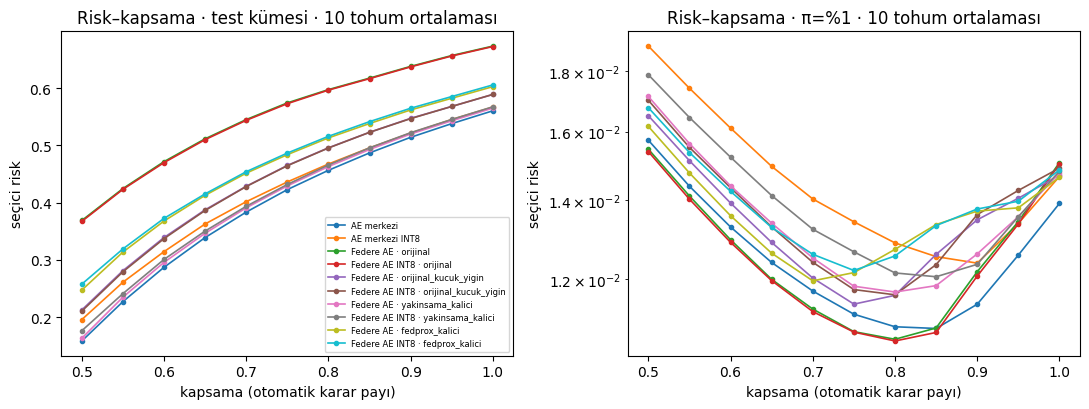

In [10]:
RCS = T["rc"].groupby(["model", "yaygınlık", "kapsama"], sort=False)["seçici_risk"].agg(["mean", "std", "count"]).reset_index()
RCS.to_csv(RUN / f"{TAG}_risk_kapsama_ozet.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, prev in zip(axs, ["test kümesi", "π=%1"]):
    for name, g in RCS[RCS["yaygınlık"] == prev].groupby("model", sort=False):
        g = g.dropna(subset=["mean"])
        ax.plot(g["kapsama"], g["mean"], marker="o", ms=3, lw=1.2, label=name)
    ax.set_xlabel("kapsama (otomatik karar payı)"); ax.set_ylabel("seçici risk"); ax.set_title(f"Risk–kapsama · {prev} · {len(DONE)} tohum ortalaması")
axs[1].set_yscale("log"); axs[0].legend(fontsize=6)
fig.tight_layout(); fig.savefig(RUN / f"{TAG}_risk_kapsama.png", dpi=150)
RCS[RCS["yaygınlık"] == "test kümesi"].pivot_table(index="model", columns="kapsama", values="mean", sort=False).round(4)

Sonuçlar: /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261112-120717_final_F4_cihaz_modeli


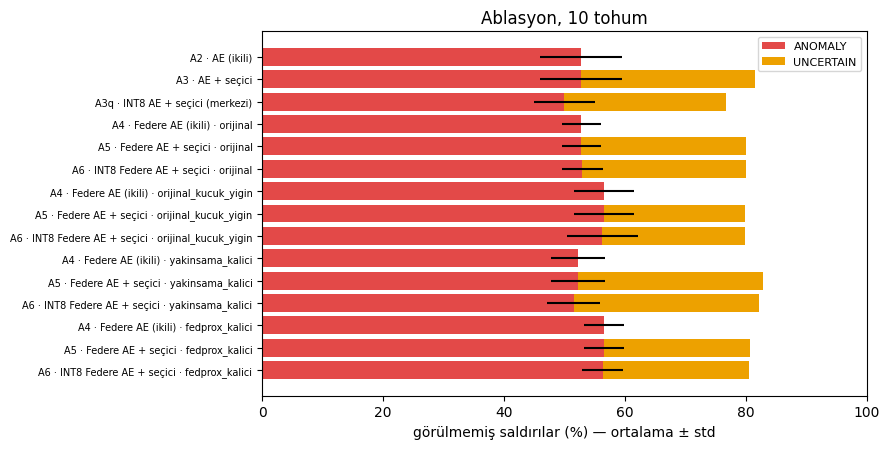

In [11]:
m_ = ABS[ABS["metrik"].isin(["görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN"])].pivot_table(index="yapılandırma", columns="metrik", values="ortalama", sort=False)
s_ = ABS[ABS["metrik"].isin(["görülmemiş_ANOMALY", "görülmemiş_UNCERTAIN"])].pivot_table(index="yapılandırma", columns="metrik", values="std", sort=False)
fig, ax = plt.subplots(figsize=(9, 4.6)); y = np.arange(len(m_))
ax.barh(y, 100 * m_["görülmemiş_ANOMALY"], xerr=100 * s_["görülmemiş_ANOMALY"], color="#e34948", label="ANOMALY")
ax.barh(y, 100 * m_["görülmemiş_UNCERTAIN"], left=100 * m_["görülmemiş_ANOMALY"], color="#eda100", label="UNCERTAIN")
ax.set_yticks(y); ax.set_yticklabels(m_.index, fontsize=7); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("görülmemiş saldırılar (%) — ortalama ± std"); ax.set_title(f"Ablasyon, {len(DONE)} tohum"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RUN / f"{TAG}_ablasyon.png", dpi=150)
utils.save_json({"tohumlar": DONE, "protokoller": cfg.fl_final_protocols, "parmak_izi": FP, "öznitelik_sayısı": int(X["benign_train"].shape[1]),
                 "not": "Gecikme Colab CPU'sunda ölçüldü; mikrodenetleyici değeri değildir. GA yalnız eğitim tohumu değişkenliğini yansıtır."},
                RUN / f"{TAG}_ozet.json")
print("Sonuçlar:", RUN)

### Cihaz (21) − tümü (53): aynı tohum, aynı yapılandırma (F3 sonuçları varsa)

In [12]:
T3, DONE3 = PL.collect(ART / "final_f3", cfg.train_seeds, FP)
if len(T3["abl"]) == 0:
    print("F3 sonuçları bulunamadı (aynı ayarlarla); karşılaştırma için önce F3 defterini çalıştırın.")
else:
    both = pd.concat([T["abl"].assign(küme="cihaz"), T3["abl"].assign(küme="tümü")])
    both["k"] = both["yapılandırma"] + " | " + both["küme"]
    names = [n for n in T["abl"]["yapılandırma"].unique() if n in set(T3["abl"]["yapılandırma"])]
    CMP = pd.concat([FZ.paired_tests(both, "k", [(f"{n} | cihaz", f"{n} | tümü") for n in names], mt)
                     for mt in ["görülmemiş_ANOMALY", "bilinen_ANOMALY", "normal_FPR", "selective_risk", "selective_risk_π=%1"]])
    CMP.to_csv(RUN / "F4_cihaz_eksi_tumu_testler.csv", index=False)
    ty = pd.concat([T["tiny"].assign(küme="cihaz"), T3["tiny"].assign(küme="tümü")])
    TYC = ty.groupby(["model", "küme"])[["parametre", "tflite_int8_KB", "tahmini_RAM_KB_int8", "gecikme_int8_µs_colab"]].mean().round(3)
    TYC.to_csv(RUN / "F4_kaynak_karsilastirma.csv"); display(TYC)
    display(CMP.round(4))

parametre  tflite_int8_KB  tahmini_RAM_KB_int8  gecikme_int8_µs_colab
model                             küme                                                                        
FedAvg-IID · fedprox_kalici       cihaz     2749.0          10.016                2.807                  1.402
                                  tümü      4829.0          12.891                4.869                  1.880
FedAvg-IID · orijinal             cihaz     2749.0          10.016                2.807                  1.797
                                  tümü      4829.0          12.891                4.869                  1.797
FedAvg-IID · orijinal_kucuk_yigin cihaz     2749.0          10.016                2.807                  1.632
                                  tümü      4829.0          12.891                4.869                  1.781
FedAvg-IID · yakinsama_kalici     cihaz     2749.0          10.016                2.807                  1.459
                                  tümü      4829.0          12.891                4.869                  2.019
Merkezi AE                        cihaz     2749.0          10.016                2.807                  1.842
                                  tümü      4829.0          12.891                4.869                  1.752

,a,b,metrik,ortalama_fark_a-b,a_daha_büyük_tohum,tohum,p_raw,p_holm
0,A4 · Federe AE (ikili) · orijinal | cihaz,A4 · Federe AE (ikili) · orijinal | tümü,görülmemiş_ANOMALY,0.5071,10,10,0.0020,0.0293
1,A4 · Federe AE (ikili) · orijinal_kucuk_yigin ...,A4 · Federe AE (ikili) · orijinal_kucuk_yigin ...,görülmemiş_ANOMALY,0.2795,10,10,0.0020,0.0293
2,A6 · INT8 Federe AE + seçici · orijinal | cihaz,A6 · INT8 Federe AE + seçici · orijinal | tümü,görülmemiş_ANOMALY,0.5076,10,10,0.0020,0.0293
3,A5 · Federe AE + seçici · orijinal | cihaz,A5 · Federe AE + seçici · orijinal | tümü,görülmemiş_ANOMALY,0.5071,10,10,0.0020,0.0293
4,A5 · Federe AE + seçici · orijinal_kucuk_yigin...,A5 · Federe AE + seçici · orijinal_kucuk_yigin...,görülmemiş_ANOMALY,0.2795,10,10,0.0020,0.0293
...,...,...,...,...,...,...,...,...
10,A5 · Federe AE + seçici · fedprox_kalici | cihaz,A5 · Federe AE + seçici · fedprox_kalici | tümü,selective_risk_π=%1,0.0007,7,10,0.2324,1.0000
11,A2 · AE (ikili) | cihaz,A2 · AE (ikili) | tümü,selective_risk_π=%1,-0.0007,3,10,0.2754,1.0000
12,A3q · INT8 AE + seçici (merkezi) | cihaz,A3q · INT8 AE + seçici (merkezi) | tümü,selective_risk_π=%1,0.0009,5,10,0.3223,1.0000
13,A3 · AE + seçici | cihaz,A3 · AE + seçici | tümü,selective_risk_π=%1,0.0004,5,10,0.7695,1.0000


In [13]:
# Colab: Drive'a yazılan tüm dosyaların kaydedildiğinden emin ol (oturumu kapatmadan önce mutlaka çalıştırın)
print("Kaydedilen ilerleme:", utils.progress(cfg))
if IN_COLAB:
    drive.flush_and_unmount()
    print("Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.")

Kaydedilen ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': True}
Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.
